In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

In [2]:
df = pd.read_csv('Walmart.csv')
df

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


In [3]:
# Get unique stores
stores = df['Store'].unique()
print(f"Number of stores: {len(stores)}")
print(f"Store IDs: {stores}")

# Create a dictionary to store data for each store
store_data = {}
for store in stores:
    store_data[store] = df[df['Store'] == store].copy()
    print(f"Store {store}: {len(store_data[store])} records")

# Alternative: Create individual DataFrames for each store
# This creates separate variables for each store
for store in stores:
    globals()[f'store_{store}_data'] = df[df['Store'] == store].copy()

print("\nData split completed! You can access:")
print("- store_data[store_id] for dictionary access")
print("- store_1_data, store_2_data, etc. for individual DataFrames")

Number of stores: 45
Store IDs: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45]
Store 1: 143 records
Store 2: 143 records
Store 3: 143 records
Store 4: 143 records
Store 5: 143 records
Store 6: 143 records
Store 7: 143 records
Store 8: 143 records
Store 9: 143 records
Store 10: 143 records
Store 11: 143 records
Store 12: 143 records
Store 13: 143 records
Store 14: 143 records
Store 15: 143 records
Store 16: 143 records
Store 17: 143 records
Store 18: 143 records
Store 19: 143 records
Store 20: 143 records
Store 21: 143 records
Store 22: 143 records
Store 23: 143 records
Store 24: 143 records
Store 25: 143 records
Store 26: 143 records
Store 27: 143 records
Store 28: 143 records
Store 29: 143 records
Store 30: 143 records
Store 31: 143 records
Store 32: 143 records
Store 33: 143 records
Store 34: 143 records
Store 35: 143 records
Store 36: 143 records
Store 37: 143 records
Store 38: 143 records
Sto

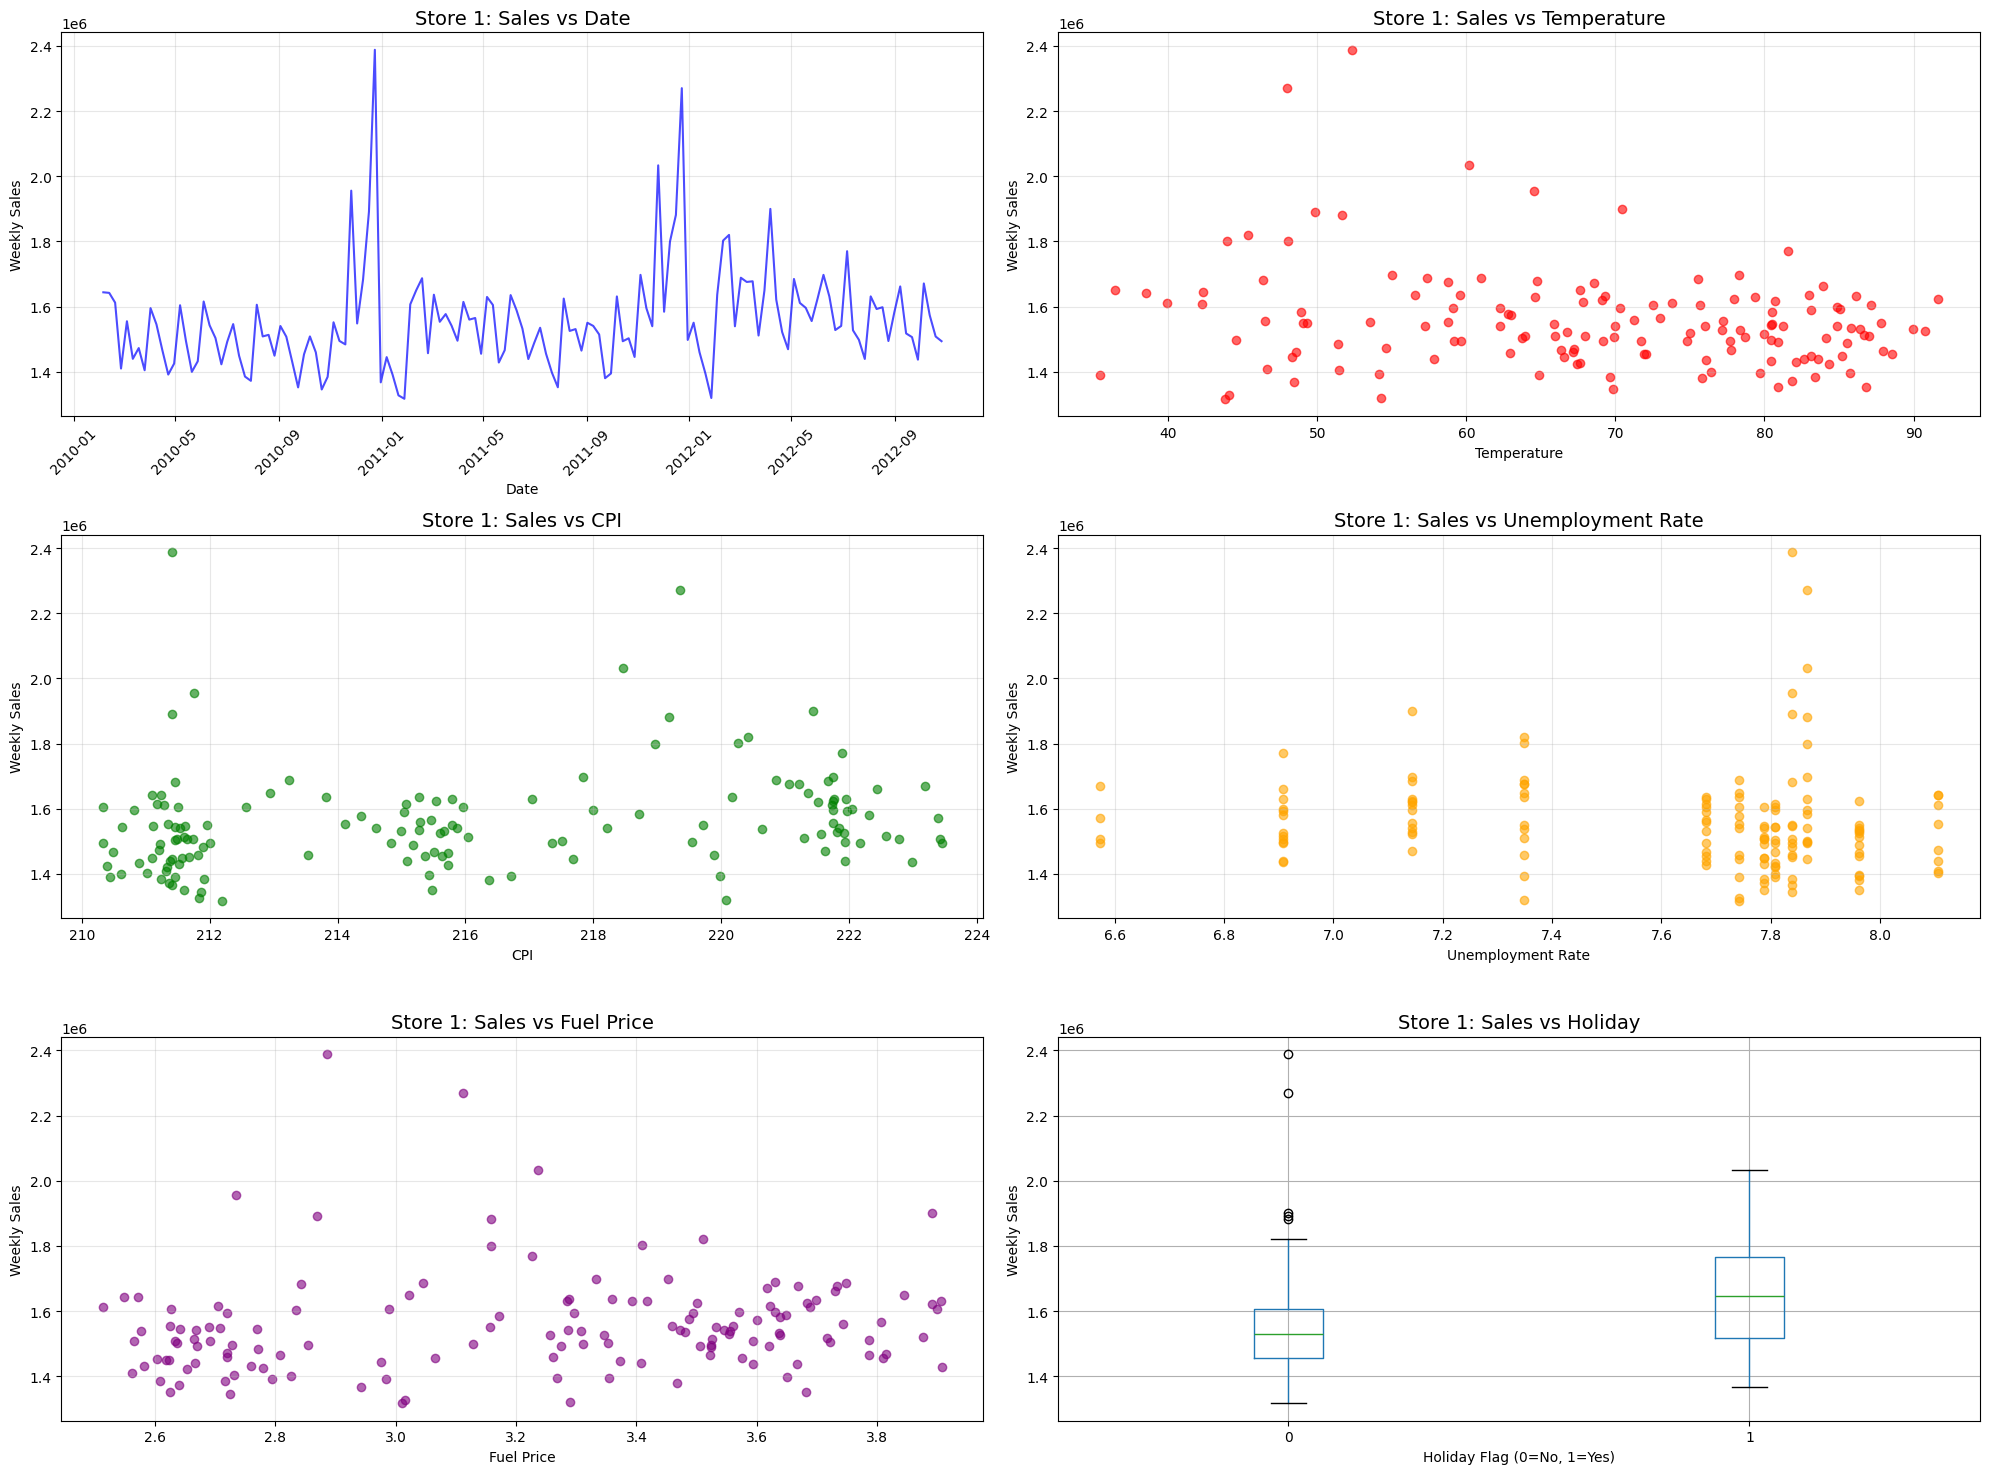

Store 1 Sales Statistics:
Total records: 143
Date range: 2010-02-05 00:00:00 to 2012-10-26 00:00:00
Average weekly sales: $1,555,264.40
Holiday vs Non-holiday sales:
              count          mean
Holiday_Flag                     
0               133  1.546957e+06
1                10  1.665748e+06


In [4]:
# Get Store 1 data
store_1 = store_data[1].copy()

# Convert Date column to datetime if it's not already
if 'Date' in store_1.columns:
    store_1['Date'] = pd.to_datetime(store_1['Date'], dayfirst=True)


# Create subplots for all visualizations
plt.figure(figsize=(20, 15))

# 1. Sales vs Date
plt.subplot(3, 2, 1)
plt.plot(store_1['Date'], store_1['Weekly_Sales'], color='blue', alpha=0.7)
plt.title('Store 1: Sales vs Date', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

# 2. Sales vs Temperature
plt.subplot(3, 2, 2)
plt.scatter(store_1['Temperature'], store_1['Weekly_Sales'], alpha=0.6, color='red')
plt.title('Store 1: Sales vs Temperature', fontsize=14)
plt.xlabel('Temperature')
plt.ylabel('Weekly Sales')
plt.grid(True, alpha=0.3)

# 3. Sales vs CPI
plt.subplot(3, 2, 3)
plt.scatter(store_1['CPI'], store_1['Weekly_Sales'], alpha=0.6, color='green')
plt.title('Store 1: Sales vs CPI', fontsize=14)
plt.xlabel('CPI')
plt.ylabel('Weekly Sales')
plt.grid(True, alpha=0.3)

# 4. Sales vs Unemployment Rate
plt.subplot(3, 2, 4)
plt.scatter(store_1['Unemployment'], store_1['Weekly_Sales'], alpha=0.6, color='orange')
plt.title('Store 1: Sales vs Unemployment Rate', fontsize=14)
plt.xlabel('Unemployment Rate')
plt.ylabel('Weekly Sales')
plt.grid(True, alpha=0.3)

# 5. Sales vs Fuel Price
plt.subplot(3, 2, 5)
plt.scatter(store_1['Fuel_Price'], store_1['Weekly_Sales'], alpha=0.6, color='purple')
plt.title('Store 1: Sales vs Fuel Price', fontsize=14)
plt.xlabel('Fuel Price')
plt.ylabel('Weekly Sales')
plt.grid(True, alpha=0.3)

# 6. Sales vs Holiday (Box plot)
plt.subplot(3, 2, 6)
store_1.boxplot(column='Weekly_Sales', by='Holiday_Flag', ax=plt.gca())
plt.title('Store 1: Sales vs Holiday', fontsize=14)
plt.xlabel('Holiday Flag (0=No, 1=Yes)')
plt.ylabel('Weekly Sales')
plt.suptitle('')  # Remove automatic title

plt.tight_layout()
plt.show()

# Print some basic statistics
print("Store 1 Sales Statistics:")
print(f"Total records: {len(store_1)}")
print(f"Date range: {store_1['Date'].min()} to {store_1['Date'].max()}")
print(f"Average weekly sales: ${store_1['Weekly_Sales'].mean():,.2f}")
print(f"Holiday vs Non-holiday sales:")
print(store_1.groupby('Holiday_Flag')['Weekly_Sales'].agg(['count', 'mean']))

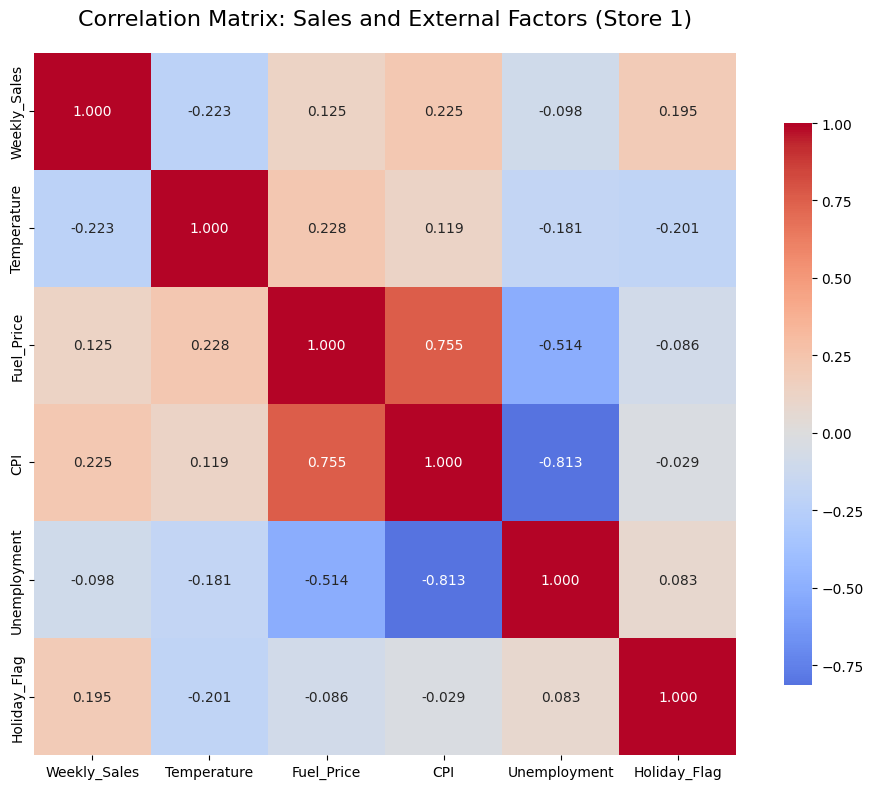

Correlation Matrix:
              Weekly_Sales  Temperature  Fuel_Price    CPI  Unemployment  \
Weekly_Sales         1.000       -0.223       0.125  0.225        -0.098   
Temperature         -0.223        1.000       0.228  0.119        -0.181   
Fuel_Price           0.125        0.228       1.000  0.755        -0.514   
CPI                  0.225        0.119       0.755  1.000        -0.813   
Unemployment        -0.098       -0.181      -0.514 -0.813         1.000   
Holiday_Flag         0.195       -0.201      -0.086 -0.029         0.083   

              Holiday_Flag  
Weekly_Sales         0.195  
Temperature         -0.201  
Fuel_Price          -0.086  
CPI                 -0.029  
Unemployment         0.083  
Holiday_Flag         1.000  

Correlations with Weekly Sales:
CPI            :   0.225
Temperature    :  -0.223
Holiday_Flag   :   0.195
Fuel_Price     :   0.125
Unemployment   :  -0.098


In [5]:
# Create correlation matrix for specified variables
correlation_vars = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Holiday_Flag']

# Select only the specified columns from store_1 data
correlation_data = store_1[correlation_vars]

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Create the correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, 
            annot=True,           # Show correlation values
            cmap='coolwarm',      # Color scheme
            center=0,             # Center colormap at 0
            square=True,          # Make cells square
            fmt='.3f',            # Format to 3 decimal places
            cbar_kws={'shrink': 0.8})

plt.title('Correlation Matrix: Sales and External Factors (Store 1)', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

# Print correlation matrix as table
print("Correlation Matrix:")
print("=" * 60)
print(correlation_matrix.round(3))

# Print strongest correlations with Weekly_Sales
print("\nCorrelations with Weekly Sales:")
print("=" * 40)
sales_correlations = correlation_matrix['Weekly_Sales'].drop('Weekly_Sales').sort_values(key=abs, ascending=False)
for var, corr in sales_correlations.items():
    print(f"{var:<15}: {corr:>7.3f}")

In [6]:
store_sales_pivot = df.pivot_table(index='Date', columns='Store', values='Weekly_Sales')
print("Aggregated Store Sales Time Series:")
print(store_sales_pivot.head())

Aggregated Store Sales Time Series:
Store               1           2          3           4          5   \
Date                                                                   
01-04-2011  1495064.75  1800171.36  374556.08  1900246.47  314316.55   
01-06-2012  1624477.58  1910092.37  432268.53  2179360.94  359867.80   
01-07-2011  1488538.09  1866243.00  368962.72  2051533.53  327093.89   
01-10-2010  1453329.50  1827440.43  358784.10  1842821.02  283178.12   
02-03-2012  1688420.76  1952555.66  469752.56  2206319.90  359206.21   

Store               6          7          8          9           10  ...  \
Date                                                                 ...   
01-04-2011  1459276.77  513409.67  878762.30  520962.14  1827733.18  ...   
01-06-2012  1681121.38  598495.02  921161.20  583648.59  1767471.48  ...   
01-07-2011  1694551.15  704344.21  883683.35  537064.03  1751369.75  ...   
01-10-2010  1328468.89  448998.73  804105.49  495692.19  1645892.97  ...   
02-

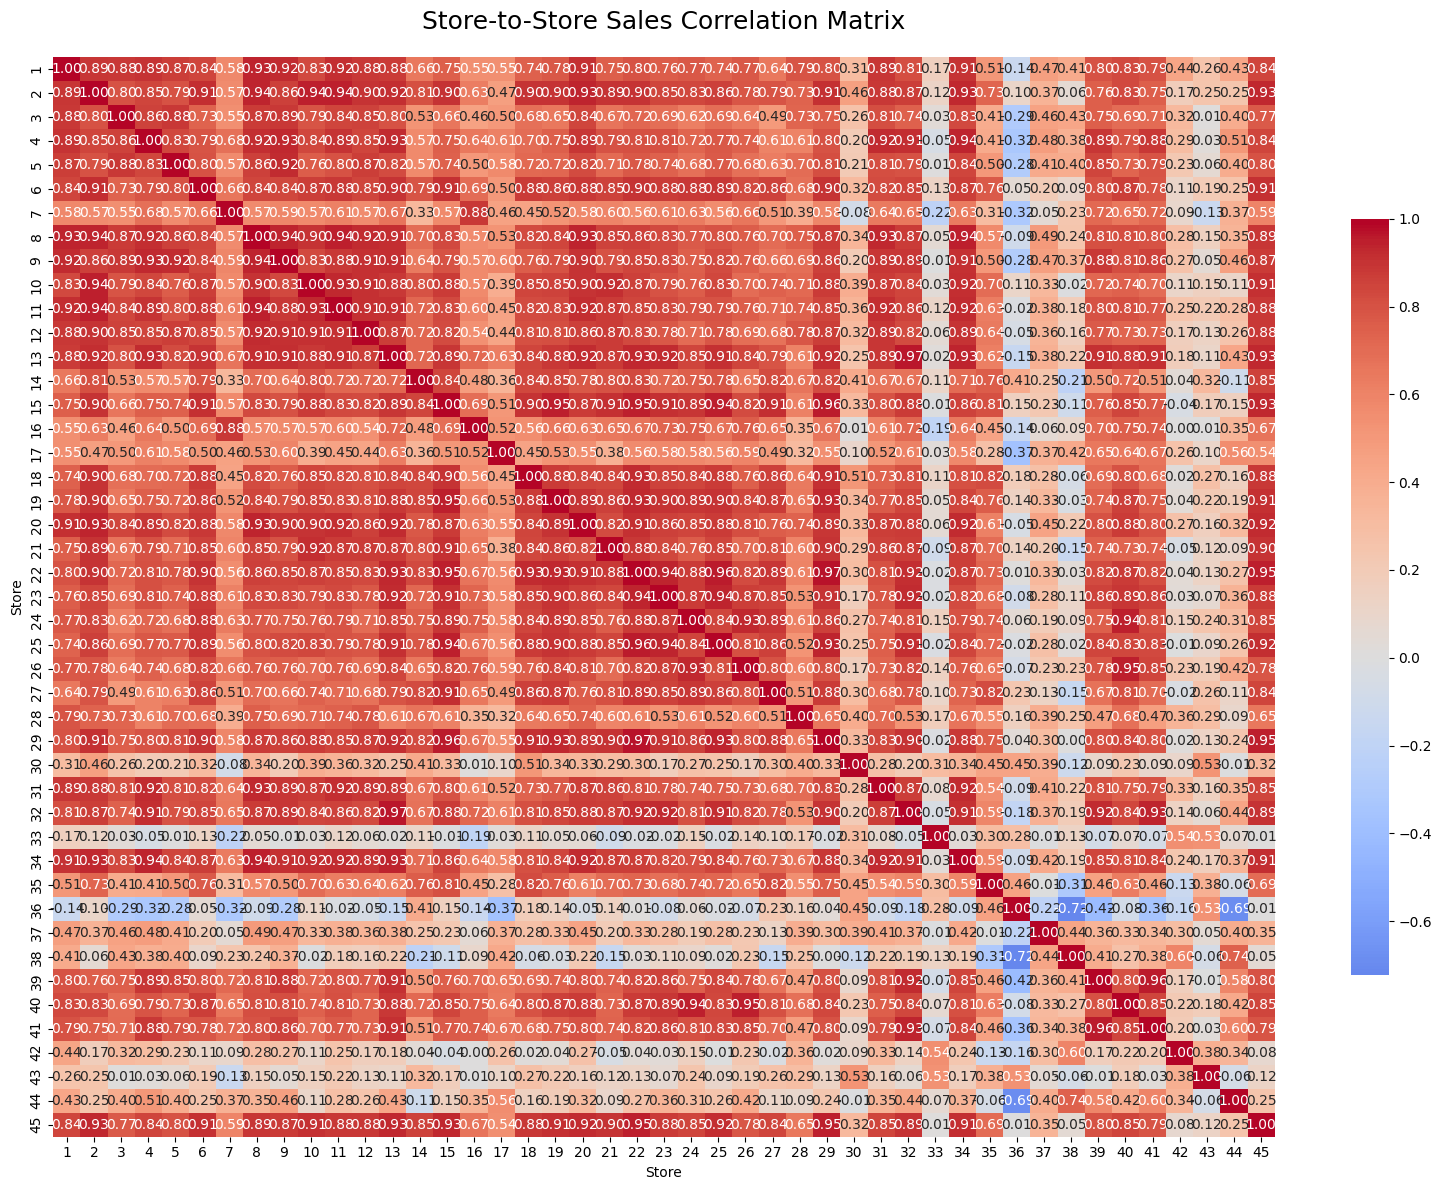

In [7]:
store_correlation_matrix = store_sales_pivot.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(store_correlation_matrix, 
            annot=True, 
            cmap='coolwarm', 
            center=0, 
            fmt='.2f', 
            cbar_kws={'shrink': 0.7})
plt.title('Store-to-Store Sales Correlation Matrix', fontsize=18, pad=20)
plt.xlabel('Store')
plt.ylabel('Store')
plt.tight_layout()
plt.show()

In [20]:
# Define the correlation threshold for creating an edge
correlation_threshold = 0.7

# Create an empty graph
G = nx.Graph()

# Add nodes for each store
for store_id in store_correlation_matrix.columns:
    G.add_node(store_id)

# Add edges based on the correlation threshold
for i in range(len(store_correlation_matrix.columns)):
    for j in range(i + 1, len(store_correlation_matrix.columns)):
        store_a = store_correlation_matrix.columns[i]
        store_b = store_correlation_matrix.columns[j]
        
        # Get the correlation value
        correlation_value = store_correlation_matrix.loc[store_a, store_b]
        
        # If correlation exceeds the threshold, add an edge with the value as a weight
        if correlation_value > correlation_threshold:
            G.add_edge(store_a, store_b, weight=correlation_value)

print(f"\nGraph constructed with {G.number_of_nodes()} nodes and {G.number_of_edges()} edges.")


# Create and save adjacency matrix from the correlation matrix
adj_matrix = (store_correlation_matrix.abs() > correlation_threshold).astype(int)
np.fill_diagonal(adj_matrix.values, 0)  # Remove self-loops
np.save('store_adjacency_matrix.npy', adj_matrix.values)
print(f"Adjacency matrix saved with shape: {adj_matrix.shape}")


Graph constructed with 45 nodes and 493 edges.
Adjacency matrix saved with shape: (45, 45)


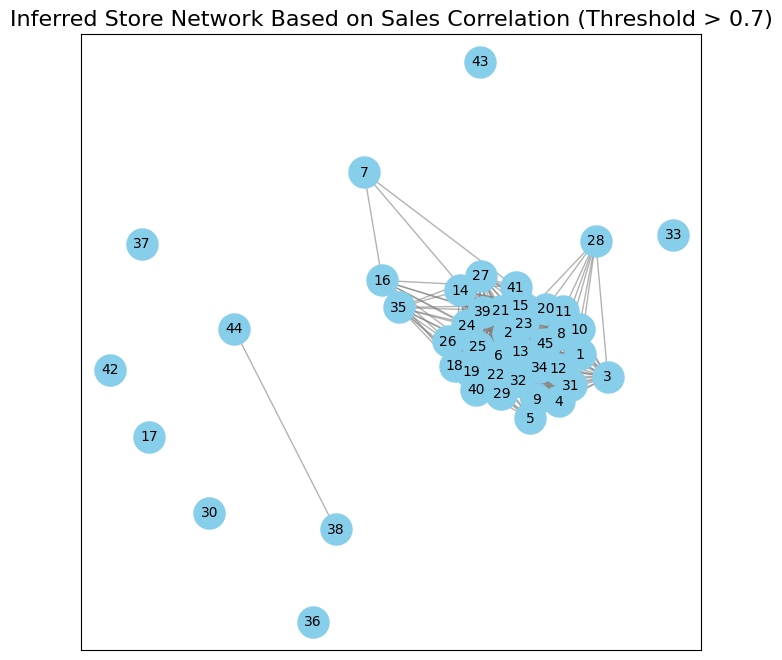

In [9]:
# Visualize the graph
plt.figure(figsize=(8, 8))

# Use a spring layout for better visualization of clusters
pos = nx.spring_layout(G, k=0.7) 

# Draw the nodes and edges
nx.draw_networkx_nodes(G, pos, node_color='skyblue', node_size=500)
nx.draw_networkx_edges(G, pos, edge_color='gray', alpha=0.6)

# Add labels to the nodes
nx.draw_networkx_labels(G, pos, font_size=10, font_family='sans-serif')

plt.title('Inferred Store Network Based on Sales Correlation (Threshold > 0.7)', fontsize=16)
plt.show()

In [ ]:
import torch
import torch.nn as nn
from sklearn.metrics import mean_squared_error, mean_absolute_error
from torch_geometric_temporal.signal import StaticGraphTemporalSignal
from torch_geometric_temporal.nn.recurrent import GConvGRU
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import joblib

In [ ]:
class STGNN(nn.Module):
    """
    Spatio-Temporal Graph Neural Network model.
    """
    def __init__(self, in_channels, hidden_channels, out_channels):
        super(STGNN, self).__init__()
        self.recurrent = GConvGRU(in_channels, hidden_channels, K=3)
        self.linear = nn.Linear(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        h = self.recurrent(x, edge_index)
        y = self.linear(h)
        return y

def create_temporal_snapshots(df, adj_matrix, window_size, prediction_horizon):
    """
    Creates temporal graph snapshots from the time series data.
    Also returns the list of store IDs in the correct order.
    """
    stores = df.pivot_table(index='Date', columns='Store', values='Weekly_Sales')
    features = stores.values
    all_store_ids = stores.columns.tolist()
    
    # scaler = StandardScaler()
    # features_scaled = scaler.fit_transform(features)
    # joblib.dump(scaler, 'sales_scaler.pkl')  
    
    edge_index = torch.tensor(np.array(np.where(adj_matrix == 1)))

    X, Y = [], []
    for i in range(len(features) - window_size - prediction_horizon + 1):
        X.append(features[i:i+window_size])
        Y.append(features[i+window_size:i+window_size+prediction_horizon])

    X = np.array(X).transpose((0, 2, 1))
    Y = np.array(Y).transpose((0, 2, 1))

    dataset = StaticGraphTemporalSignal(edge_index, np.ones(edge_index.shape[1]), X, Y)
    return dataset, all_store_ids

def train_val_test_split(dataset, train_ratio=0.7, val_ratio=0.15):
    """
    Splits the dataset chronologically into training, validation, and test sets.
    """
    # Convert dataset to list first to get the length
    dataset_list = [snapshot for snapshot in dataset]
    total_snapshots = len(dataset_list)
    
    train_end = int(total_snapshots * train_ratio)
    val_end = int(total_snapshots * (train_ratio + val_ratio))

    train_dataset = dataset_list[:train_end]
    val_dataset = dataset_list[train_end:val_end]
    test_dataset = dataset_list[val_end:]

    return train_dataset, val_dataset, test_dataset


In [26]:
def plot_predictions(model, dataset, device, all_store_ids, stores_to_plot):
    """
    Visualizes the model's predictions against the actual values for selected stores.
    """
    model.eval()
    all_y_true_list = []
    all_y_pred_list = []
    with torch.no_grad():
        for snapshot in dataset:
            x, y = snapshot.x.to(device), snapshot.y.to(device)
            out = model(x, snapshot.edge_index.to(device))
            all_y_true_list.append(y.cpu().numpy())
            all_y_pred_list.append(out.cpu().numpy())

    all_y_true = np.concatenate(all_y_true_list, axis=0)
    all_y_pred = np.concatenate(all_y_pred_list, axis=0)

    # Only squeeze if the last dimension is 1 and we have more than 1 dimension
    if all_y_true.ndim > 1 and all_y_true.shape[-1] == 1:
        all_y_true = all_y_true.squeeze(-1)
        all_y_pred = all_y_pred.squeeze(-1)

    num_plots = len(stores_to_plot)
    plt.figure(figsize=(15, 3 * num_plots))
    
    for i, store_id in enumerate(stores_to_plot):
        plt.subplot(num_plots, 1, i + 1)
        try:
            store_idx = all_store_ids.index(store_id)
            
            # Handle both 1D and 2D cases
            if all_y_true.ndim == 1:
                # If 1D, we can't plot by store, just plot the single series
                plt.plot(all_y_true, label='Actual Sales')
                plt.plot(all_y_pred, label='Predicted Sales', linestyle='--')
                plt.title(f'Sales: Actual vs. Predicted (Test Set)')
                break  # Only plot once for 1D data
            else:
                # 2D case - plot specific store
                plt.plot(all_y_true[:, store_idx], label='Actual Sales')
                plt.plot(all_y_pred[:, store_idx], label='Predicted Sales', linestyle='--')
                plt.title(f'Store {store_id}: Actual vs. Predicted Sales (Test Set)')
            
            plt.ylabel('Weekly Sales')
            plt.legend()
        except ValueError:
            print(f"Warning: Store ID {store_id} not found in the data. Skipping plot.")
        except IndexError as e:
            print(f"Warning: IndexError for Store {store_id}: {e}. Data shape: {all_y_true.shape}")

    plt.xlabel('Time Step (in test set)')
    plt.tight_layout()
    plt.show()


In [27]:
def main():
    """
    Main function to run data preparation, model training, validation, and testing.
    """
    # --- Data Preparation ---
    df = pd.read_csv('Walmart.csv')
    df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
    adj_matrix = np.load('store_adjacency_matrix.npy')

    # Parameters
    window_size = 4
    prediction_horizon = 1
    train_ratio = 0.7
    val_ratio = 0.15

    dataset, all_store_ids = create_temporal_snapshots(df, adj_matrix, window_size, prediction_horizon)
    train_dataset, val_dataset, test_dataset = train_val_test_split(dataset, train_ratio, val_ratio)

    # --- Model Initialization ---
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    model = STGNN(in_channels=window_size, hidden_channels=32, out_channels=prediction_horizon).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    # --- Training and Validation ---
    print("\n--- Training and Validation ---")
    best_val_loss = float('inf')
    for epoch in range(10):
        model.train()
        total_loss = 0
        for snapshot in train_dataset:
            x, y = snapshot.x.to(device), snapshot.y.to(device)
            optimizer.zero_grad()
            out = model(x, snapshot.edge_index.to(device))
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        avg_train_loss = total_loss / len(train_dataset)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for snapshot in val_dataset:
                x, y = snapshot.x.to(device), snapshot.y.to(device)
                out = model(x, snapshot.edge_index.to(device))
                val_loss += criterion(out, y).item()
        avg_val_loss = val_loss / len(val_dataset)

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), 'best_stgnn_model.pth')

        print(f"Epoch {epoch+1:03d}, Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}")

    print("\nTraining complete. Best model saved to 'best_stgnn_model.pth'")

    # --- Testing Phase ---
    print("\n--- Testing Phase ---")
    model.load_state_dict(torch.load('best_stgnn_model.pth'))
    model.eval()

    all_y_true, all_y_pred = [], []
    with torch.no_grad():
        for snapshot in test_dataset:
            x, y = snapshot.x.to(device), snapshot.y.to(device)
            out = model(x, snapshot.edge_index.to(device))
            all_y_true.append(y)
            all_y_pred.append(out)

    all_y_true = torch.cat(all_y_true, dim=0).cpu()
    all_y_pred = torch.cat(all_y_pred, dim=0).cpu()

    test_mse = mean_squared_error(all_y_true, all_y_pred)
    test_rmse = np.sqrt(test_mse)
    test_mae = mean_absolute_error(all_y_true, all_y_pred)

    print(f"Test MSE: {test_mse:.4f}")
    print(f"Test RMSE: {test_rmse:.4f}")
    print(f"Test MAE: {test_mae:.4f}")

    # --- Visualization ---
    print("\nGenerating prediction plots for selected stores...")
    stores_to_plot = [1, 4, 14, 20] # Select a few stores to visualize
    plot_predictions(model, test_dataset, device, all_store_ids, stores_to_plot)


Using device: cuda

--- Training and Validation ---
Epoch 001, Train Loss: 1437524532150.1030, Val Loss: 1355212284294.0952
Epoch 002, Train Loss: 1437496389505.3196, Val Loss: 1355185486311.6191
Epoch 003, Train Loss: 1437468884654.1855, Val Loss: 1355159056579.0476
Epoch 004, Train Loss: 1437441582491.7114, Val Loss: 1355132792246.8572
Epoch 005, Train Loss: 1437414345865.2371, Val Loss: 1355106527914.6667
Epoch 006, Train Loss: 1437387175450.3918, Val Loss: 1355080301031.6191
Epoch 007, Train Loss: 1437360003684.2886, Val Loss: 1355054139684.5715
Epoch 008, Train Loss: 1437332879887.8350, Val Loss: 1355027993941.3333
Epoch 009, Train Loss: 1437305751361.9795, Val Loss: 1355001785782.8572
Epoch 010, Train Loss: 1437278646483.1340, Val Loss: 1354975658764.1904

Training complete. Best model saved to 'best_stgnn_model.pth'

--- Testing Phase ---


C:\Users\HP\AppData\Local\Temp\ipykernel_16956\1317929019.py:61: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_stgnn_model.pth'))


Test MSE: 1362417156096.0000
Test RMSE: 1167226.2660
Test MAE: 1038709.5000

Generating prediction plots for selected stores...


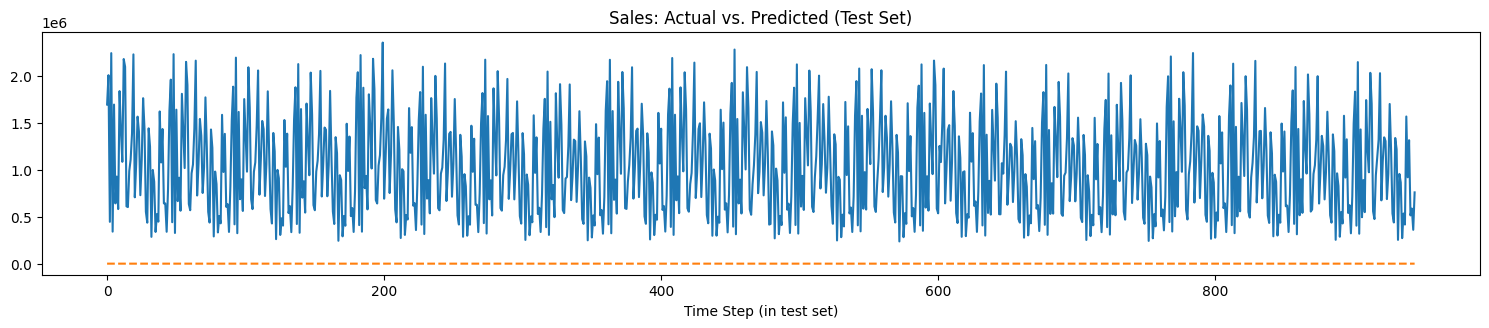

In [28]:
main()